# Segmentación de comercios con K-means

## Objetivo

Construir un modelo de segmentación que agrupe los comercios de acuerdo con su comportamiento durante los últimos seis meses.

La segmentación tendrá en cuenta la recencia, la cantidad de transacciones, los meses activos, las ventas acumuladas y la tendencia transaccional. El resultado permitirá identificar comercios con comportamientos similares y proponer campañas orientadas al incremento de las ventas y las comisiones generadas por la plataforma.

Para determinar la cantidad de segmentos se evaluarán diferentes valores de K mediante el método del codo, el coeficiente de Silhouette y el índice Davies-Bouldin.


#### 1. Cargue de datos 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", palette="muted")

print("Librerías importadas correctamente")

Librerías importadas correctamente


In [2]:
# Ruta de la base preparada para el modelo
ruta_base = Path(
    "../data/processed/base_modelo_segmentacion.csv"
)

# Cargar la base
base_modelo = pd.read_csv(
    ruta_base,
    dtype={"Id_comercio": "string"}
)

print("Filas y columnas:", base_modelo.shape)
print("Comercios únicos:", base_modelo["Id_comercio"].nunique())

display(base_modelo.head())

Filas y columnas: (3015, 27)
Comercios únicos: 3015


,Id_comercio,Numero_terminales,Categoria,Subcategoria,Ciudad,Fecha_primera_vinculacion,Fecha_creacion_comercio,Fecha_primera_transaccion,Ventas_acumuladas,Ventas_ultimo_mes_reportado,Tx_2020_12,Tx_2021_01,Tx_2021_02,Tx_2021_03,Tx_2021_04,Tx_2021_05,Total_transacciones_6m,Meses_activos,Ultimo_mes_activo,Recencia_meses,Transacciones_primeros_3m,Transacciones_ultimos_3m,Tendencia_transacciones,Comision_acumulada,Comision_ultimo_mes_reportado,Venta_promedio_por_transaccion,Ventas_por_terminal
0,003QDVFJCJ,1,Comercio detallista,Ropa / Accesorios,Bogotá D.C.,2021-03-26,2021-03-26,2021-03-26,6542000,1240000,0,0,0,5,9,16,30,3,2021-05-01,0,0,30,30,"327,100.00","62,000.00","218,066.67","6,542,000.00"
1,008LJH6YHN,1,Belleza y cuidado personal,Spa,Bogotá D.C.,2021-02-10,2021-02-10,2021-02-10,4380000,1102000,0,0,2,5,1,2,10,4,2021-05-01,0,2,8,6,"219,000.00","55,100.00","438,000.00","4,380,000.00"
2,00B3DGV62G,1,Comercio detallista,Auto partes,Bogotá D.C.,2021-03-03,2021-03-03,2021-03-03,11892500,1297000,0,0,0,22,22,21,65,3,2021-05-01,0,0,65,65,"594,625.00","64,850.00","182,961.54","11,892,500.00"
3,00ILW1BB3Y,1,Comercio detallista,Tienda naturista,Bogotá D.C.,2021-03-24,2021-03-24,2021-03-24,372500,74500,0,0,0,1,2,5,8,3,2021-05-01,0,0,8,8,"18,625.00","3,725.00","46,562.50","372,500.00"
4,01AK7UX4UU,1,Comercio detallista,Tecnología,Mosquera,2021-03-30,2021-03-30,2021-03-30,165500,0,0,0,0,1,3,0,4,2,2021-04-01,1,0,4,4,"8,275.00",0.00,"41,375.00","165,500.00"


#### 2. Selección de variables

#### Justificación de las variables

Las variables del modelo fueron seleccionadas porque representan diferentes dimensiones del comportamiento de los comercios durante los seis meses analizados:

* Recencia_meses: indica cuántos meses han pasado desde la última actividad del comercio.
* Total_transacciones_6m: representa la frecuencia con la que el comercio utilizó la plataforma.
* Meses_activos: muestra la continuidad de la actividad durante el periodo.
* Ventas_acumuladas: representa el valor económico generado por el comercio.
* Tendencia_transacciones: permite identificar si la actividad aumentó o disminuyó entre los primeros y los últimos tres meses.

No se incluyeron las comisiones porque corresponden directamente al 5 % de las ventas y, por lo tanto, no agregan información diferente. Tampoco se incluyeron simultáneamente las transacciones mensuales y sus variables resumidas, ya que esto daría mayor peso al comportamiento transaccional dentro del cálculo de las distancias.

La categoría, subcategoría, ciudad y número de terminales se conservarán para describir los segmentos después de ejecutar el modelo, pero no se utilizarán para calcularlos. La categoría y la ciudad son variables cualitativas, mientras que el número de terminales presenta poca variabilidad porque la mayoría de los comercios tiene una sola terminal.



In [3]:
# Variables seleccionadas para construir los segmentos
variables_modelo = [
    "Recencia_meses",
    "Total_transacciones_6m",
    "Meses_activos",
    "Ventas_acumuladas",
    "Tendencia_transacciones"
]

# Crear la matriz de datos del modelo
X = base_modelo[variables_modelo].copy()

display(X.head())

,Recencia_meses,Total_transacciones_6m,Meses_activos,Ventas_acumuladas,Tendencia_transacciones
0,0,30,3,6542000,30
1,0,10,4,4380000,6
2,0,65,3,11892500,65
3,0,8,3,372500,8
4,1,4,2,165500,4


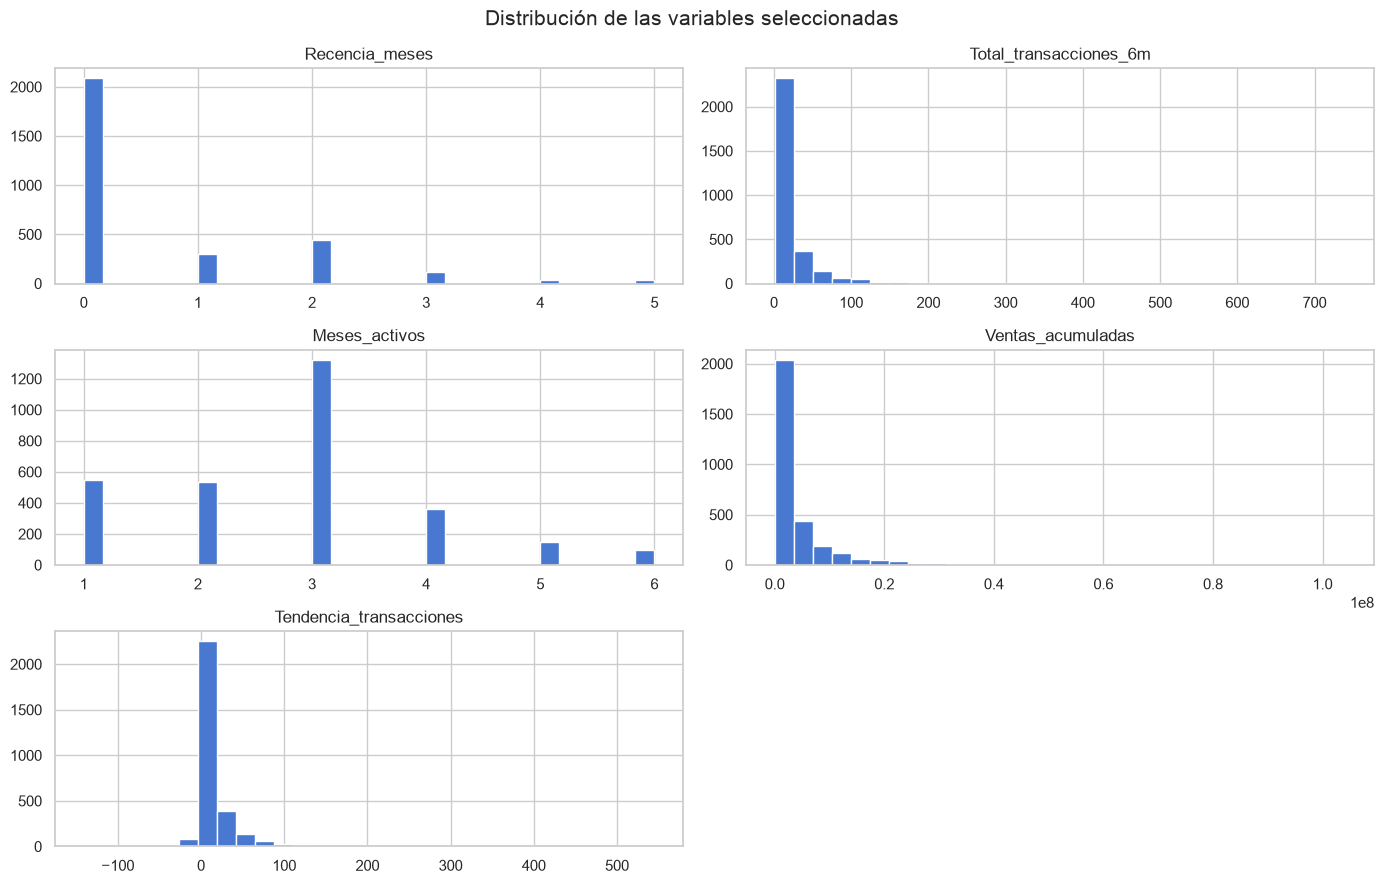

In [4]:
# Distribución de las variables seleccionadas
X.hist(
    figsize=(14, 9),
    bins=30,
    edgecolor="white"
)

plt.suptitle(
    "Distribución de las variables seleccionadas",
    fontsize=15
)

plt.tight_layout()
plt.show()

,Recencia_meses,Total_transacciones_6m,Meses_activos,Ventas_acumuladas,Tendencia_transacciones
Recencia_meses,1.00,-0.69,-0.76,-0.61,-0.66
Total_transacciones_6m,-0.69,1.00,0.78,0.80,0.80
Meses_activos,-0.76,0.78,1.00,0.69,0.48
Ventas_acumuladas,-0.61,0.80,0.69,1.00,0.59
Tendencia_transacciones,-0.66,0.80,0.48,0.59,1.00


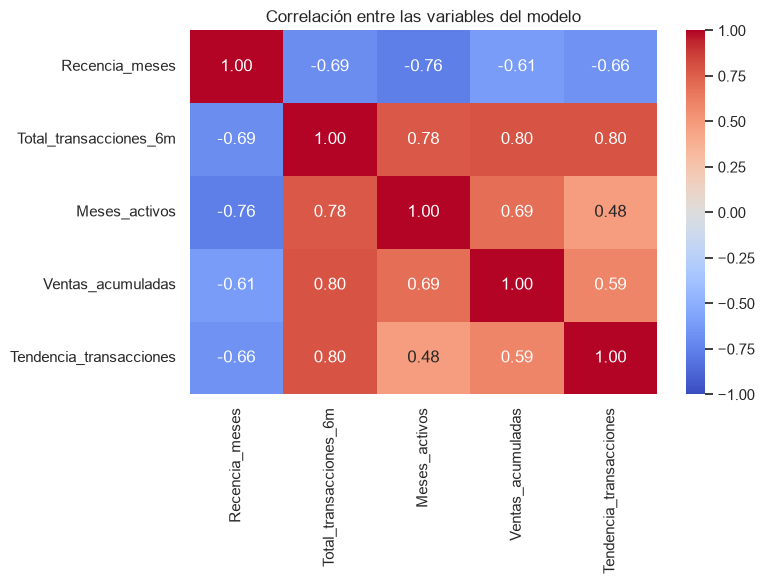

In [5]:
# Correlación entre variables
correlaciones = X.corr(method="spearman")

display(correlaciones.round(2))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlación entre las variables del modelo")
plt.tight_layout()
plt.show()

 #### 3. Preparación de los datos

In [6]:
# Transformación de variables 
X_transformado = X.copy()

# Reducir el efecto de los valores extremos
X_transformado["Total_transacciones_6m"] = np.log1p(
    X_transformado["Total_transacciones_6m"]
)

X_transformado["Ventas_acumuladas"] = np.log1p(
    X_transformado["Ventas_acumuladas"]
)

# Transformar la tendencia conservando valores positivos y negativos
X_transformado["Tendencia_transacciones"] = (
    np.sign(X_transformado["Tendencia_transacciones"])
    * np.log1p(
        np.abs(X_transformado["Tendencia_transacciones"])
    )
)

display(X_transformado.head())

,Recencia_meses,Total_transacciones_6m,Meses_activos,Ventas_acumuladas,Tendencia_transacciones
0,0,3.43,3,15.69,3.43
1,0,2.40,4,15.29,1.95
2,0,4.19,3,16.29,4.19
3,0,2.20,3,12.83,2.20
4,1,1.61,2,12.02,1.61


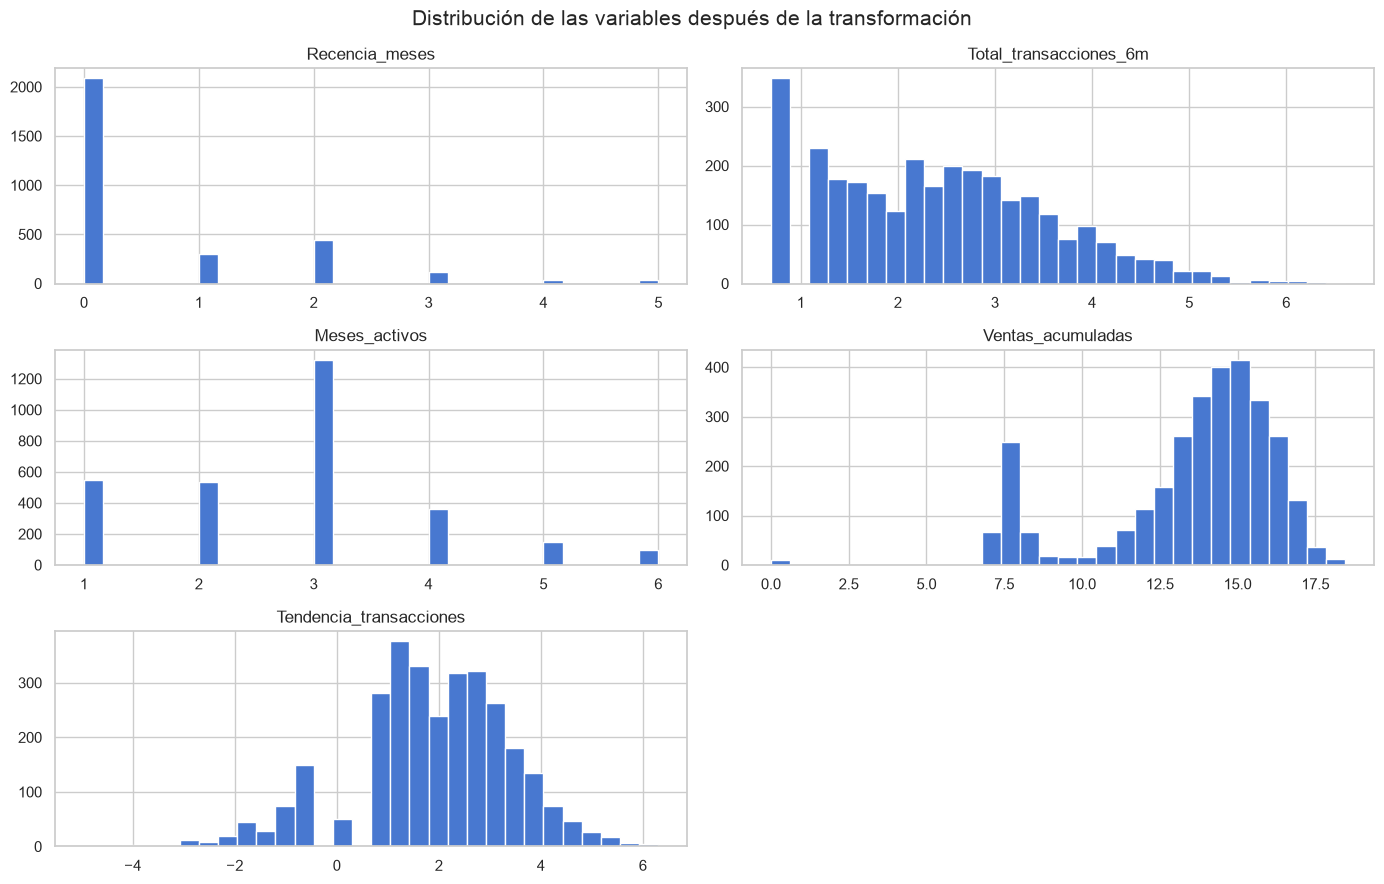

In [7]:
X_transformado.hist(
    figsize=(14, 9),
    bins=30,
    edgecolor="white"
)

plt.suptitle(
    "Distribución de las variables después de la transformación",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [8]:
# Estandarizar las variables
escalador = StandardScaler()

X_escalado = escalador.fit_transform(
    X_transformado
)

# Convertir el resultado nuevamente en una tabla
X_escalado = pd.DataFrame(
    X_escalado,
    columns=variables_modelo,
    index=base_modelo.index
)

display(X_escalado.head())

,Recencia_meses,Total_transacciones_6m,Meses_activos,Ventas_acumuladas,Tendencia_transacciones
0,-0.57,0.88,0.19,0.77,1.00
1,-0.57,-0.01,1.02,0.63,0.04
2,-0.57,1.53,0.19,0.98,1.48
3,-0.57,-0.18,0.19,-0.24,0.20
4,0.35,-0.69,-0.64,-0.52,-0.17


#### 4. Evaluación del número de segmentos

In [9]:
# Probar diferentes cantidades de segmentos
valores_k = range(1, 9)

inercias = []
silhouettes = []
davies_bouldin = []

for k in valores_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=123,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_escalado)

    inercias.append(modelo.inertia_)

    if k > 1:
        silhouettes.append(
            silhouette_score(X_escalado, etiquetas)
        )

        davies_bouldin.append(
            davies_bouldin_score(X_escalado, etiquetas)
        )

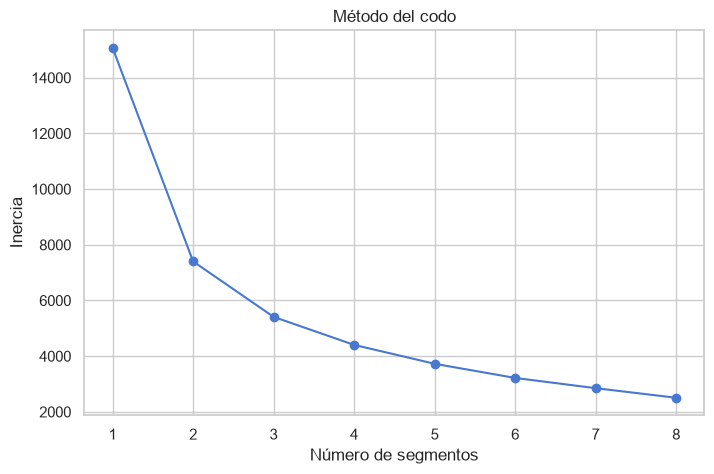

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    valores_k,
    inercias,
    marker="o"
)

plt.title("Método del codo")
plt.xlabel("Número de segmentos")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.show()

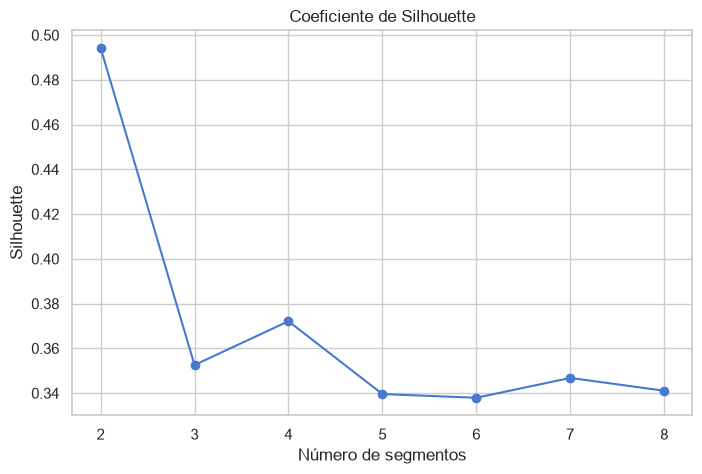

In [11]:
valores_k_metricas = range(2, 9)

plt.figure(figsize=(8, 5))

plt.plot(
    valores_k_metricas,
    silhouettes,
    marker="o"
)

plt.title("Coeficiente de Silhouette")
plt.xlabel("Número de segmentos")
plt.ylabel("Silhouette")
plt.xticks(valores_k_metricas)
plt.show()

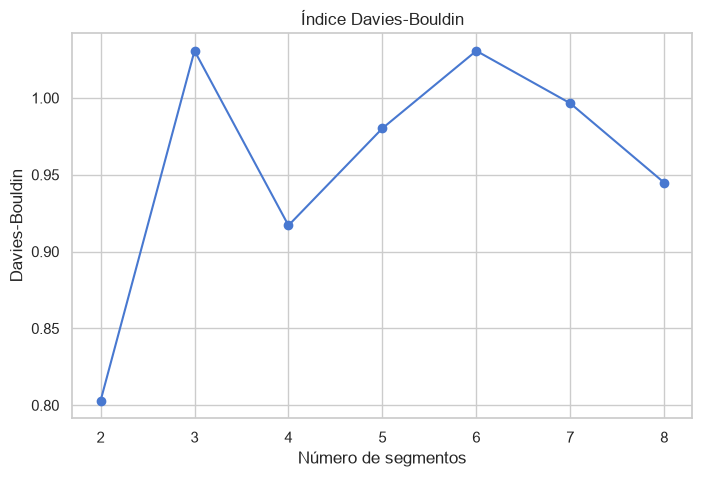

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    valores_k_metricas,
    davies_bouldin,
    marker="o"
)

plt.title("Índice Davies-Bouldin")
plt.xlabel("Número de segmentos")
plt.ylabel("Davies-Bouldin")
plt.xticks(valores_k_metricas)
plt.show()

In [13]:
resultados_k = pd.DataFrame({
    "K": list(valores_k_metricas),
    "Silhouette": silhouettes,
    "Davies_Bouldin": davies_bouldin,
    "Inercia": inercias[1:]
})

display(
    resultados_k.round(3)
)

,K,Silhouette,Davies_Bouldin,Inercia
0,2,0.49,0.80,"7,401.88"
1,3,0.35,1.03,"5,410.10"
2,4,0.37,0.92,"4,404.37"
3,5,0.34,0.98,"3,725.35"
4,6,0.34,1.03,"3,217.47"
5,7,0.35,1.00,"2,849.46"
6,8,0.34,0.94,"2,505.11"


Se evaluaron soluciones entre 2 y 8 segmentos utilizando el método del codo, el coeficiente de Silhouette y el índice Davies-Bouldin.

La solución con dos segmentos obtuvo los mejores resultados estadísticos, con un Silhouette de 0,49 y un Davies-Bouldin de 0,80. Sin embargo, dividir los comercios solamente en dos grupos produciría una segmentación muy general y limitaría la creación de campañas diferenciadas.

La solución con cuatro segmentos obtuvo un Silhouette de 0,37 y un Davies-Bouldin de 0,92. Aunque la separación entre los grupos es moderada, presenta el mejor Silhouette entre las alternativas de tres o más segmentos. Además, en el método del codo se observa que después de cuatro grupos la reducción de la inercia comienza a ser menor.

Por esta razón, se seleccionan cuatro segmentos, buscando un equilibrio entre la calidad estadística del modelo y la posibilidad de identificar perfiles comerciales útiles para el negocio.

#### 5. Entrenamiento del modelo

In [14]:
# Evaluación de parámetros
resultados_parametros = []

for inicializacion in ["k-means++", "random"]:
    for numero_intentos in [10, 20, 30]:

        modelo_prueba = KMeans(
            n_clusters=4,
            init=inicializacion,
            n_init=numero_intentos,
            max_iter=300,
            tol=1e-4,
            random_state=123
        )

        etiquetas = modelo_prueba.fit_predict(X_escalado)

        resultados_parametros.append({
            "Inicializacion": inicializacion,
            "Numero_intentos": numero_intentos,
            "Silhouette": silhouette_score(
                X_escalado,
                etiquetas
            ),
            "Davies_Bouldin": davies_bouldin_score(
                X_escalado,
                etiquetas
            ),
            "Inercia": modelo_prueba.inertia_,
            "Iteraciones": modelo_prueba.n_iter_
        })

resultados_parametros = pd.DataFrame(resultados_parametros)

resultados_parametros = resultados_parametros.sort_values(
    by=["Silhouette", "Davies_Bouldin"],
    ascending=[False, True]
)

display(resultados_parametros.round(3))

,Inicializacion,Numero_intentos,Silhouette,Davies_Bouldin,Inercia,Iteraciones
1,k-means++,20,0.37,0.92,"4,404.37",10
2,k-means++,30,0.37,0.92,"4,404.29",11
4,random,20,0.37,0.92,"4,404.28",16
5,random,30,0.37,0.92,"4,404.28",16
3,random,10,0.37,0.92,"4,404.38",17
0,k-means++,10,0.37,0.92,"4,404.37",12


Las configuraciones evaluadas presentaron resultados muy similares, con un coeficiente de Silhouette de 0,37 y un índice Davies-Bouldin de 0,92. Esto indica que la segmentación es estable frente a diferentes formas de inicializar el modelo.

Se seleccionó la inicialización k-means con 20 intentos, debido a que obtuvo los mejores resultados sin aumentar innecesariamente el tiempo de ejecución. Además, el modelo logró converger en solamente 10 iteraciones.

In [15]:
# Entrenar el modelo
modelo_kmeans = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=20,
    max_iter=300,
    tol=1e-4,
    random_state=123
)

# Asignar cada comercio a un segmento
segmentos = modelo_kmeans.fit_predict(X_escalado)

# Agregar el segmento a la base original
comercios_segmentados = base_modelo.copy()
comercios_segmentados["Segmento"] = segmentos

display(comercios_segmentados.head())

,Id_comercio,Numero_terminales,Categoria,Subcategoria,Ciudad,Fecha_primera_vinculacion,Fecha_creacion_comercio,Fecha_primera_transaccion,Ventas_acumuladas,Ventas_ultimo_mes_reportado,Tx_2020_12,Tx_2021_01,Tx_2021_02,Tx_2021_03,Tx_2021_04,Tx_2021_05,Total_transacciones_6m,Meses_activos,Ultimo_mes_activo,Recencia_meses,Transacciones_primeros_3m,Transacciones_ultimos_3m,Tendencia_transacciones,Comision_acumulada,Comision_ultimo_mes_reportado,Venta_promedio_por_transaccion,Ventas_por_terminal,Segmento
0,003QDVFJCJ,1,Comercio detallista,Ropa / Accesorios,Bogotá D.C.,2021-03-26,2021-03-26,2021-03-26,6542000,1240000,0,0,0,5,9,16,30,3,2021-05-01,0,0,30,30,"327,100.00","62,000.00","218,066.67","6,542,000.00",2
1,008LJH6YHN,1,Belleza y cuidado personal,Spa,Bogotá D.C.,2021-02-10,2021-02-10,2021-02-10,4380000,1102000,0,0,2,5,1,2,10,4,2021-05-01,0,2,8,6,"219,000.00","55,100.00","438,000.00","4,380,000.00",3
2,00B3DGV62G,1,Comercio detallista,Auto partes,Bogotá D.C.,2021-03-03,2021-03-03,2021-03-03,11892500,1297000,0,0,0,22,22,21,65,3,2021-05-01,0,0,65,65,"594,625.00","64,850.00","182,961.54","11,892,500.00",2
3,00ILW1BB3Y,1,Comercio detallista,Tienda naturista,Bogotá D.C.,2021-03-24,2021-03-24,2021-03-24,372500,74500,0,0,0,1,2,5,8,3,2021-05-01,0,0,8,8,"18,625.00","3,725.00","46,562.50","372,500.00",3
4,01AK7UX4UU,1,Comercio detallista,Tecnología,Mosquera,2021-03-30,2021-03-30,2021-03-30,165500,0,0,0,0,1,3,0,4,2,2021-04-01,1,0,4,4,"8,275.00",0.00,"41,375.00","165,500.00",3


In [16]:
# Comercios asignados a cada segmento
distribucion_segmentos = (
    comercios_segmentados["Segmento"]
    .value_counts()
    .sort_index()
    .reset_index()
)

distribucion_segmentos.columns = [
    "Segmento",
    "Cantidad_comercios"
]

# Participación porcentual
distribucion_segmentos["Porcentaje"] = (
    distribucion_segmentos["Cantidad_comercios"]
    / distribucion_segmentos["Cantidad_comercios"].sum()
    * 100
).round(2)

display(distribucion_segmentos)

print(
    "Total de comercios:",
    distribucion_segmentos["Cantidad_comercios"].sum()
)

,Segmento,Cantidad_comercios,Porcentaje
0,0,234,7.76
1,1,622,20.63
2,2,1002,33.23
3,3,1157,38.37


Total de comercios: 3015


#### 6. Perfil de los segmentos


- Cantidad_comercios: tamaño del grupo.
- Recencia_promedio: hace cuántos meses fue su última actividad.
- Transacciones_promedio: frecuencia de uso de la API.
- Meses_activos_promedio: continuidad de los comercios.
- Ventas_promedio: valor económico promedio por comercio.
- Ventas_totales: aporte total del segmento.
- Tendencia_promedio:
    - Positiva: la actividad está creciendo.
    - Cercana a cero: permanece estable.
    - Negativa: está disminuyendo.
- Comision_total: ingresos estimados para la marca por el 5 % de las ventas.

In [17]:
# Perfil de cada segmento
perfil_segmentos = (
    comercios_segmentados
    .groupby("Segmento")
    .agg(
        Cantidad_comercios=("Id_comercio", "nunique"),
        Recencia_promedio=("Recencia_meses", "mean"),
        Transacciones_promedio=("Total_transacciones_6m", "mean"),
        Meses_activos_promedio=("Meses_activos", "mean"),
        Ventas_promedio=("Ventas_acumuladas", "mean"),
        Ventas_totales=("Ventas_acumuladas", "sum"),
        Tendencia_promedio=("Tendencia_transacciones", "mean")
    )
    .reset_index()
)

# Comisión total generada por cada segmento
perfil_segmentos["Comision_total"] = (
    perfil_segmentos["Ventas_totales"] * 0.05
)

display(perfil_segmentos.round(2))

,Segmento,Cantidad_comercios,Recencia_promedio,Transacciones_promedio,Meses_activos_promedio,Ventas_promedio,Ventas_totales,Tendencia_promedio,Comision_total
0,0,234,0.14,36.31,5.08,"9,990,380.04",2337748930,-0.53,"116,887,446.50"
1,1,622,2.45,2.00,1.16,"349,045.06",217106025,0.25,"10,855,301.25"
2,2,1002,0.01,50.22,3.37,"8,634,342.56",8651611250,41.41,"432,580,562.50"
3,3,1157,0.26,6.99,2.66,"1,749,510.91",2024184127,6.12,"101,209,206.35"


In [18]:
# Revisar las medianas de cada segmento
medianas_segmentos = (
    comercios_segmentados
    .groupby("Segmento")
    [
        [
            "Recencia_meses",
            "Total_transacciones_6m",
            "Meses_activos",
            "Ventas_acumuladas",
            "Tendencia_transacciones"
        ]
    ]
    .median()
    .round(2)
)

display(medianas_segmentos)

,Recencia_meses,Total_transacciones_6m,Meses_activos,Ventas_acumuladas,Tendencia_transacciones
Segmento,,,,,
0,0.00,23.00,5.00,"6,460,500.00",1.00
1,2.00,1.00,1.00,"2,000.00",1.00
2,0.00,29.00,3.00,"5,143,500.00",26.00
3,0.00,6.00,3.00,"997,550.00",5.00



**Segmento 0 — Consolidados de alto valor:** el comercio típico realizó 23 transacciones, estuvo activo cinco meses y registró ventas acumuladas de $6,46 millones. Su tendencia mediana es positiva en una transacción, aunque el promedio fue de -0,53. Esto indica que la mayoría permanece estable, pero algunos comercios con caídas fuertes reducen el promedio.

**Segmento 1 — Comercios por reactivar:** el comercio típico realizó solamente una transacción, estuvo activo un mes, lleva dos meses sin actividad y registró ventas de apenas $2.000. Es claramente el grupo que necesita estrategias de reactivación.

**Segmento 2 — Líderes en crecimiento:** el comercio típico realizó 29 transacciones, tuvo actividad reciente, registró ventas de $5,14 millones y presentó un crecimiento de 26 transacciones. Es el grupo con mayor crecimiento y aporte total a las comisiones.

**Segmento 3 — Activos con potencial:** el comercio típico tuvo actividad reciente, realizó seis transacciones y registró ventas de $997.550. Su tendencia es positiva en cinco transacciones, por lo que está creciendo, aunque todavía genera un valor moderado.


#### 7. Análisis cualitativo de segmentos

In [19]:
# Contar comercios por segmento y categoría
categorias_segmentos = (
    comercios_segmentados
    .groupby(["Segmento", "Categoria"])
    .size()
    .reset_index(name="Cantidad_comercios")
)

# Calcular el porcentaje dentro de cada segmento
categorias_segmentos["Porcentaje_segmento"] = (
    categorias_segmentos["Cantidad_comercios"]
    / categorias_segmentos
        .groupby("Segmento")["Cantidad_comercios"]
        .transform("sum")
    * 100
).round(2)

# Mostrar las cinco categorías principales de cada segmento
top_categorias_segmentos = (
    categorias_segmentos
    .sort_values(
        ["Segmento", "Cantidad_comercios"],
        ascending=[True, False]
    )
    .groupby("Segmento")
    .head(5)
)

display(top_categorias_segmentos)

,Segmento,Categoria,Cantidad_comercios,Porcentaje_segmento
2,0,Comercio detallista,134,57.26
4,0,Servicios,47,20.09
1,0,Belleza y cuidado personal,18,7.69
0,0,Alimentos y bebidas,17,7.26
3,0,Reparación y limpieza,14,5.98
9,1,Comercio detallista,277,44.53
12,1,Servicios,140,22.51
7,1,Alimentos y bebidas,75,12.06
11,1,Reparación y limpieza,44,7.07
8,1,Belleza y cuidado personal,39,6.27


- Consolidados de alto valor: fidelización especialmente en comercio detallista y servicios.
- Por reactivar: campañas de recuperación principalmente para comercio detallista y servicios.
- Líderes en crecimiento: oportunidades importantes en comercio detallista y alimentos y bebidas.
- Activos con potencial: incentivar más transacciones en comercio detallista y servicios.

In [20]:
# Contar comercios por segmento y ciudad
ciudades_segmentos = (
    comercios_segmentados
    .groupby(["Segmento", "Ciudad"])
    .size()
    .reset_index(name="Cantidad_comercios")
)

# Calcular el porcentaje dentro de cada segmento
ciudades_segmentos["Porcentaje_segmento"] = (
    ciudades_segmentos["Cantidad_comercios"]
    / ciudades_segmentos
        .groupby("Segmento")["Cantidad_comercios"]
        .transform("sum")
    * 100
).round(2)

# Mostrar las cinco ciudades principales de cada segmento
top_ciudades_segmentos = (
    ciudades_segmentos
    .sort_values(
        ["Segmento", "Cantidad_comercios"],
        ascending=[True, False]
    )
    .groupby("Segmento")
    .head(5)
    .reset_index(drop=True)
)

display(top_ciudades_segmentos)

,Segmento,Ciudad,Cantidad_comercios,Porcentaje_segmento
0,0,Bogotá D.C.,191,81.62
1,0,Soacha,32,13.68
2,0,Melgar,3,1.28
3,0,Chía,2,0.85
4,0,Pereira,2,0.85
5,1,Bogotá D.C.,483,77.65
6,1,Cali,41,6.59
7,1,Soacha,27,4.34
8,1,Fusagasugá,14,2.25
9,1,Chía,9,1.45


- Consolidados de alto valor: fidelización principalmente en Bogotá y Soacha.
- Por reactivar: campañas de recuperación en Bogotá, con acciones complementarias en Cali y Soacha.
- Líderes en crecimiento: oportunidades de expansión principalmente en Bogotá y Soacha.
- Activos con potencial: incentivar una mayor frecuencia de uso especialmente en Bogotá.

Se evidencia que a parte de Bogotá, Soacha tiene una alta influencia en los segmentos 

#### 8. Análisis de ventas y comisiones 

In [21]:
resumen_aporte = perfil_segmentos[
    [
        "Segmento",
        "Cantidad_comercios",
        "Ventas_totales",
        "Comision_total"
    ]
].copy()

# Agregar nombres comerciales
nombres_segmentos = {
    0: "Consolidados de alto valor",
    1: "Comercios por reactivar",
    2: "Líderes en crecimiento",
    3: "Activos con potencial"
}
resumen_aporte["Nombre_segmento"] = (
    resumen_aporte["Segmento"].map(nombres_segmentos)
)
# Agregar el nombre del segmento a cada comercio
comercios_segmentados["Nombre_segmento"] = (
    comercios_segmentados["Segmento"].map(nombres_segmentos)
)

# Calcular participaciones
resumen_aporte["Porcentaje_comercios"] = (
    resumen_aporte["Cantidad_comercios"]
    / resumen_aporte["Cantidad_comercios"].sum()
    * 100
)

resumen_aporte["Porcentaje_ventas"] = (
    resumen_aporte["Ventas_totales"]
    / resumen_aporte["Ventas_totales"].sum()
    * 100
)

resumen_aporte["Porcentaje_comision"] = (
    resumen_aporte["Comision_total"]
    / resumen_aporte["Comision_total"].sum()
    * 100
)

display(resumen_aporte.round(2))

,Segmento,Cantidad_comercios,Ventas_totales,Comision_total,Nombre_segmento,Porcentaje_comercios,Porcentaje_ventas,Porcentaje_comision
0,0,234,2337748930,"116,887,446.50",Consolidados de alto valor,7.76,17.67,17.67
1,1,622,217106025,"10,855,301.25",Comercios por reactivar,20.63,1.64,1.64
2,2,1002,8651611250,"432,580,562.50",Líderes en crecimiento,33.23,65.39,65.39
3,3,1157,2024184127,"101,209,206.35",Activos con potencial,38.37,15.30,15.30


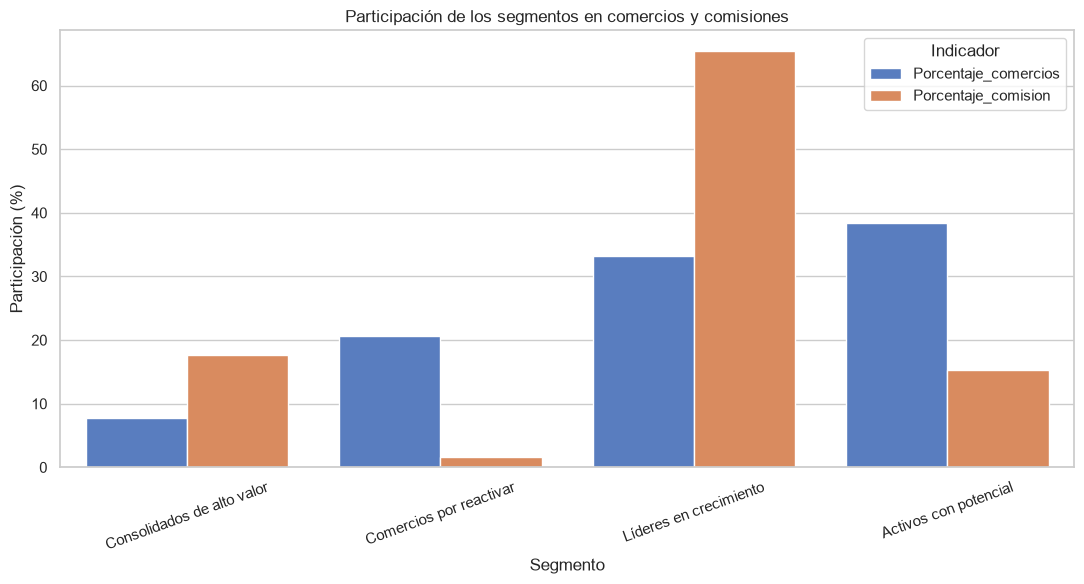

In [22]:
datos_grafica = resumen_aporte.melt(
    id_vars="Nombre_segmento",
    value_vars=[
        "Porcentaje_comercios",
        "Porcentaje_comision"
    ],
    var_name="Indicador",
    value_name="Porcentaje"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=datos_grafica,
    x="Nombre_segmento",
    y="Porcentaje",
    hue="Indicador"
)

plt.title("Participación de los segmentos en comercios y comisiones")
plt.xlabel("Segmento")
plt.ylabel("Participación (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

- **Consolidados de alto valor** representan solamente el 7,76 % de los comercios y aportan el 17,67 % de las comisiones, lo que confirma su alto valor individual.
- **Comercios por reactivar** representan el 20,63 % de la base y aportan solo el 1,64 % de las comisiones, por lo que requieren campañas de recuperación antes de esperar un aporte significativo.
- **Líderes en crecimiento** reúnen el 33,23 % de los comercios, pero generan el 65,39 % de las ventas y comisiones, por lo que constituyen el principal motor de ingresos.
- **Activos con potencial** son el grupo más grande, con el 38,37 % de los comercios, pero generan apenas el 15,30 % de las comisiones. Esto evidencia una oportunidad para aumentar su frecuencia transaccional.

La conclusión más importante es que tener más comercios no significa necesariamente generar más comisión. Los líderes en crecimiento son menos numerosos que los activos con potencial, pero generan aproximadamente cuatro veces más comisión. Por eso las campañas deben diseñarse de manera diferente para cada segmento.


In [23]:
columnas_principales = [
    "Id_comercio",
    "Segmento",
    "Nombre_segmento",
    "Categoria",
    "Subcategoria",
    "Ciudad",
    "Numero_terminales",
    "Recencia_meses",
    "Total_transacciones_6m",
    "Meses_activos",
    "Ventas_acumuladas",
    "Comision_acumulada",
    "Tendencia_transacciones"
]

columnas_principales = [
    columna for columna in columnas_principales
    if columna in comercios_segmentados.columns
]

otras_columnas = [
    columna for columna in comercios_segmentados.columns
    if columna not in columnas_principales
]

comercios_segmentados = comercios_segmentados[
    columnas_principales + otras_columnas
]

In [24]:
comercios_segmentados.head(10)

,Id_comercio,Segmento,Nombre_segmento,Categoria,Subcategoria,Ciudad,Numero_terminales,Recencia_meses,Total_transacciones_6m,Meses_activos,Ventas_acumuladas,Comision_acumulada,Tendencia_transacciones,Fecha_primera_vinculacion,Fecha_creacion_comercio,Fecha_primera_transaccion,Ventas_ultimo_mes_reportado,Tx_2020_12,Tx_2021_01,Tx_2021_02,Tx_2021_03,Tx_2021_04,Tx_2021_05,Ultimo_mes_activo,Transacciones_primeros_3m,Transacciones_ultimos_3m,Comision_ultimo_mes_reportado,Venta_promedio_por_transaccion,Ventas_por_terminal
0,003QDVFJCJ,2,Líderes en crecimiento,Comercio detallista,Ropa / Accesorios,Bogotá D.C.,1,0,30,3,6542000,"327,100.00",30,2021-03-26,2021-03-26,2021-03-26,1240000,0,0,0,5,9,16,2021-05-01,0,30,"62,000.00","218,066.67","6,542,000.00"
1,008LJH6YHN,3,Activos con potencial,Belleza y cuidado personal,Spa,Bogotá D.C.,1,0,10,4,4380000,"219,000.00",6,2021-02-10,2021-02-10,2021-02-10,1102000,0,0,2,5,1,2,2021-05-01,2,8,"55,100.00","438,000.00","4,380,000.00"
2,00B3DGV62G,2,Líderes en crecimiento,Comercio detallista,Auto partes,Bogotá D.C.,1,0,65,3,11892500,"594,625.00",65,2021-03-03,2021-03-03,2021-03-03,1297000,0,0,0,22,22,21,2021-05-01,0,65,"64,850.00","182,961.54","11,892,500.00"
3,00ILW1BB3Y,3,Activos con potencial,Comercio detallista,Tienda naturista,Bogotá D.C.,1,0,8,3,372500,"18,625.00",8,2021-03-24,2021-03-24,2021-03-24,74500,0,0,0,1,2,5,2021-05-01,0,8,"3,725.00","46,562.50","372,500.00"
4,01AK7UX4UU,3,Activos con potencial,Comercio detallista,Tecnología,Mosquera,1,1,4,2,165500,"8,275.00",4,2021-03-30,2021-03-30,2021-03-30,0,0,0,0,1,3,0,2021-04-01,0,4,0.00,"41,375.00","165,500.00"
5,01OB36KP84,3,Activos con potencial,Alimentos y bebidas,Restaurante / Café,Bogotá D.C.,1,0,4,2,104000,"5,200.00",-2,2020-12-10,2020-12-10,2020-12-10,25500,3,0,0,0,0,1,2021-05-01,3,1,"1,275.00","26,000.00","104,000.00"
6,01PFUX10Z9,2,Líderes en crecimiento,Alimentos y bebidas,Comida rápida,Bogotá D.C.,1,0,51,3,1104380,"55,219.00",51,2021-03-29,2021-03-29,2021-03-29,208250,0,0,0,1,28,22,2021-05-01,0,51,"10,412.50","21,654.51","1,104,380.00"
7,024EE2F9LX,1,Comercios por reactivar,Comercio detallista,Auto partes,Soacha,1,2,1,1,2000,100.00,1,2021-03-01,2021-03-01,2021-03-01,0,0,0,0,1,0,0,2021-03-01,0,1,0.00,"2,000.00","2,000.00"
8,0254G0047E,3,Activos con potencial,Comercio detallista,Óptica,Bogotá D.C.,1,0,8,3,2265000,"113,250.00",8,2021-03-24,2021-03-24,2021-03-24,0,0,0,0,3,3,2,2021-05-01,0,8,0.00,"283,125.00","2,265,000.00"
9,0355B2ZSMZ,2,Líderes en crecimiento,Alimentos y bebidas,Restaurante / Café,Suaita,1,0,18,3,1610100,"80,505.00",18,2021-03-27,2021-03-27,2021-03-27,270100,0,0,0,1,11,6,2021-05-01,0,18,"13,505.00","89,450.00","1,610,100.00"


In [25]:
ruta_salida = Path(
    "../data/processed/comercios_segmentados.csv"
)

comercios_segmentados.to_csv(
    ruta_salida,
    index=False
)